#   FNAN 632 - Project Part 4

Karim Khadir


## Setup


In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1 . Download Daily ETF Prices

In [2]:
prices = yf.download(
    ["IVV", "AGG"],
    start="2005-12-01",
    end="2026-01-01",
    auto_adjust=False
)

prices.head()

[*********************100%***********************]  2 of 2 completed


Price       Adj Close                 Close                    High  \
Ticker            AGG        IVV        AGG         IVV         AGG   
Date                                                                  
2005-12-01  51.535320  86.375282  99.699997  126.750000  100.110001   
2005-12-02  51.535320  86.511581  99.699997  126.949997   99.879997   
2005-12-05  51.561169  86.245789  99.750000  126.559998   99.860001   
2005-12-06  51.649036  86.422966  99.919998  126.820000  100.000000   
2005-12-07  51.581806  86.007278  99.790001  126.209999  100.059998   

Price                         Low                    Open              Volume  \
Ticker             IVV        AGG         IVV         AGG         IVV     AGG   
Date                                                                            
2005-12-01  127.029999  99.519997  126.070000   99.900002  126.070000  520700   
2005-12-02  127.089996  99.589996  126.550003   99.839996  126.790001  151700   
2005-12-05  126.800003  99.360001  126.209999   99.800003  126.720001  308600   
2005-12-06  127.750000  99.669998  126.699997   99.860001  127.129997  186000   
2005-12-07  126.900002  99.669998  125.730003  100.000000  126.849998  200800   

Price                
Ticker          IVV  
Date                 
2005-12-01   730300  
2005-12-02  1623800  
2005-12-05  3200500  
2005-12-06  1784500  
2005-12-07   998100

# 2. Calculate Daily Returns 

I followed Project 2, Exercise 2, to calculate daily returns, filter the dates, and report the sample size. I used Adjusted Close because Project 4 asks for adjusted prices.


In [3]:
returns = prices["Adj Close"].pct_change()
returns = returns[returns.index >= "2006-01-01"]
returns = returns[returns.index < "2026-01-01"]

display(pd.DataFrame(returns))
print("Sample size:", len(returns))

Ticker,AGG,IVV
Date,,
2006-01-03,0.000497,0.017326
2006-01-04,0.002384,0.005204
2006-01-05,0.000000,0.000784
2006-01-06,-0.002280,0.008308
2006-01-09,0.001093,0.002565
...,...,...
2025-12-24,0.002204,0.003502
2025-12-26,0.000200,-0.000173
2025-12-29,0.001200,-0.003404


Sample size: 5031


## Question 3.
I used the cumulative growth approach from Project 1, Exercise 4, and the histogram example from Project 2, Exercise 3.

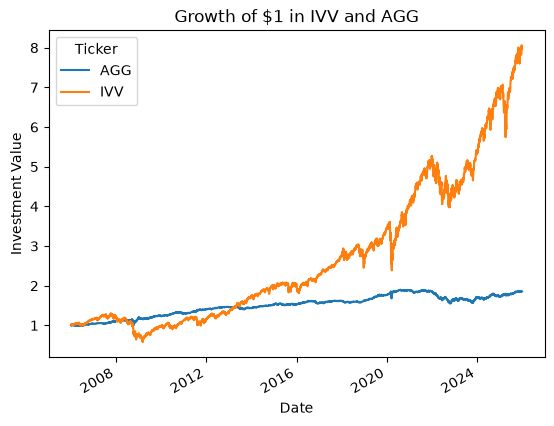

In [4]:
investment = (1 + returns).cumprod()

investment.plot()
plt.title("Growth of $1 in IVV and AGG")
plt.xlabel("Date")
plt.ylabel("Investment Value")
plt.show()

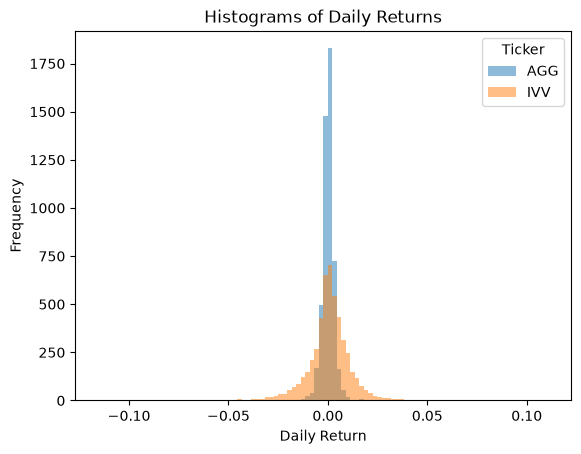

In [5]:
returns.plot.hist(bins=100, alpha=0.5)
plt.title("Histograms of Daily Returns")
plt.xlabel("Daily Return")
plt.show()

The growth plot shows that IVV grew more than AGG, but it also moved around more. 

AGG’s returns are usually closer to zero, although it has more extreme returns in its tails, especially on the negative side. 

That suggests AGG is more negatively skewed and has higher kurtosis.

<small>Reference: Project 1, Exercise 6; Project 2, Exercises 3–4; Project 4, Questions 3–4.</small>

## Question 4

I calculated the summary statistics and quantiles for IVV and AGG.

<small>Reference: Project 2, Exercise 4; Project 1, Exercises 6–9.</small>

In [6]:
stats = pd.DataFrame(
    [
        returns.mean(),
        returns.std(),
        returns.skew(),
        returns.kurt(),
        returns.mean() / returns.std(),
        returns.quantile(.01),
        returns.quantile(.05),
        returns.quantile(.10),
        returns.quantile(.90),
        returns.quantile(.95),
        returns.quantile(.99),
    ],
    index=[
        "Average Return",
        "Standard Deviation",
        "Skewness",
        "Excess Kurtosis",
        "Average Return / Standard Deviation",
        "1% Quantile",
        "5% Quantile",
        "10% Quantile",
        "90% Quantile",
        "95% Quantile",
        "99% Quantile",
    ],
)

stats

Ticker,AGG,IVV
Average Return,0.000129,0.000486
Standard Deviation,0.003347,0.012125
Skewness,-1.880638,-0.211923
Excess Kurtosis,50.610111,12.060730
Average Return / Standard Deviation,0.038425,0.040096
1% Quantile,-0.008191,-0.035061
5% Quantile,-0.004610,-0.018172
10% Quantile,-0.003081,-0.011870
90% Quantile,0.003301,0.012136
95% Quantile,0.004456,0.016677


IVV had a higher average daily return than AGG, but it also had more daily variation. 

The average return-to-standard-deviation ratios were close: about 0.040 for IVV and 0.038 for AGG. IVV’s 1% and 99% quantiles were farther from zero, showing larger daily gains and losses.

 AGG was more negatively skewed, suggesting greater downside asymmetry, and its higher excess kurtosis means it had more extreme returns overall.

<small>Reference: Project 2, Exercise 4; Project 1, Exercises 6–9.</small>

## Question 5



In [7]:
returns.corr()

Ticker,AGG,IVV
Ticker,,
AGG,1.00000,-0.02221
IVV,-0.02221,1.00000


The correlation between IVV and AGG was about -0.022, so their daily returns had almost no linear relationship in this sample. 

Because they did not generally move together, combining them could provide diversification and help reduce portfolio volatility.

<small>Reference: Project 2, Exercise 13; Project 4, Questions 5–6.</small>

## Question 6

I calculated the returns for a portfolio that holds 60% IVV and 40% AGG, rebalanced each day.

<small>Reference: Project 2, Exercise 14.</small>

In [8]:
portfolio_6040 = 0.60 * returns["IVV"] + 0.40 * returns["AGG"]

portfolio_6040.head()

Date
2006-01-03    0.010594
2006-01-04    0.004076
2006-01-05    0.000470
2006-01-06    0.004073
2006-01-09    0.001976
dtype: float64

In [9]:
stats["60/40 Rebalanced"] = [
    portfolio_6040.mean(),
    portfolio_6040.std(),
    portfolio_6040.skew(),
    portfolio_6040.kurt(),
    portfolio_6040.mean() / portfolio_6040.std(),
    portfolio_6040.quantile(.01),
    portfolio_6040.quantile(.05),
    portfolio_6040.quantile(.10),
    portfolio_6040.quantile(.90),
    portfolio_6040.quantile(.95),
    portfolio_6040.quantile(.99),
]

stats

Ticker,AGG,IVV,60/40 Rebalanced
Average Return,0.000129,0.000486,0.000343
Standard Deviation,0.003347,0.012125,0.007368
Skewness,-1.880638,-0.211923,-0.102481
Excess Kurtosis,50.610111,12.060730,14.312480
Average Return / Standard Deviation,0.038425,0.040096,0.046573
1% Quantile,-0.008191,-0.035061,-0.021795
5% Quantile,-0.004610,-0.018172,-0.010689
10% Quantile,-0.003081,-0.011870,-0.006924
90% Quantile,0.003301,0.012136,0.007291
95% Quantile,0.004456,0.016677,0.010310


The 60/40 portfolio’s average return was between IVV’s and AGG’s. Its standard deviation was lower than IVV’s (0.0074 vs 0.0121), but higher than AGG’s (0.0033). 

Its average return-to-standard-deviation ratio was about 0.047, a little bit higher than either ETF’s.

 Its excess kurtosis was 14.3, between AGG’s 50.6 and IVV’s 12.1.

<small>Reference: Project 2, Exercise 14.</small>

## Question 7

I calculated the returns and changing weights for a 60/40 portfolio that is not rebalanced.

<small>Reference: Project 1, Exercise 4; Project 2, Exercise 14.</small>

In [10]:
adj_close = prices["Adj Close"]
start_prices = adj_close.loc[adj_close.index < "2006-01-01"].iloc[-1]

ivv_value = 0.60 * adj_close["IVV"] / start_prices["IVV"]
agg_value = 0.40 * adj_close["AGG"] / start_prices["AGG"]

buy_hold_value = ivv_value + agg_value
buy_hold_returns = buy_hold_value.pct_change().loc["2006-01-01":"2025-12-31"].dropna()

buy_hold_weights = pd.DataFrame({
    "IVV": ivv_value / buy_hold_value,
    "AGG": agg_value / buy_hold_value,
}).loc["2006-01-01":"2025-12-31"]

display(buy_hold_returns.head())
display(buy_hold_weights.head())

Date
2006-01-03    0.010594
2006-01-04    0.004087
2006-01-05    0.000474
2006-01-06    0.004124
2006-01-09    0.001987
dtype: float64

,IVV,AGG
Date,,
2006-01-03,0.603997,0.396003
2006-01-04,0.604668,0.395332
2006-01-05,0.604856,0.395144
2006-01-06,0.607376,0.392624
2006-01-09,0.607726,0.392274


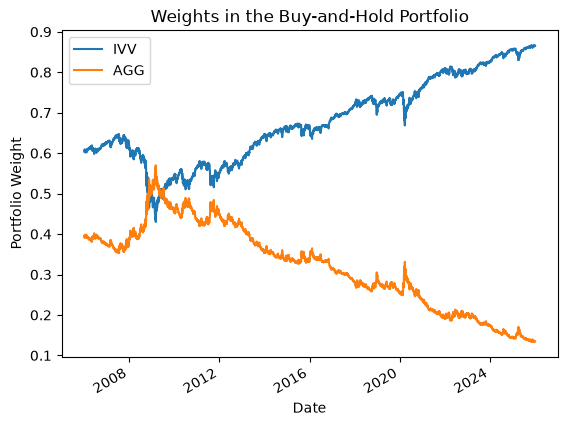

,IVV,AGG
Date,,
2025-12-24,0.866748,0.133252
2025-12-26,0.866705,0.133295
2025-12-29,0.866172,0.133828
2025-12-30,0.866052,0.133948
2025-12-31,0.865489,0.134511


In [11]:
buy_hold_weights.plot()
plt.title("Weights in the Buy-and-Hold Portfolio")
plt.xlabel("Date")
plt.ylabel("Portfolio Weight")
plt.show()

buy_hold_weights.tail()

In [12]:
stats["60/40 Buy and Hold"] = [
    buy_hold_returns.mean(),
    buy_hold_returns.std(),
    buy_hold_returns.skew(),
    buy_hold_returns.kurt(),
    buy_hold_returns.mean() / buy_hold_returns.std(),
    buy_hold_returns.quantile(.01),
    buy_hold_returns.quantile(.05),
    buy_hold_returns.quantile(.10),
    buy_hold_returns.quantile(.90),
    buy_hold_returns.quantile(.95),
    buy_hold_returns.quantile(.99),
]

stats

Ticker,AGG,IVV,60/40 Rebalanced,60/40 Buy and Hold
Average Return,0.000129,0.000486,0.000343,0.000371
Standard Deviation,0.003347,0.012125,0.007368,0.007934
Skewness,-1.880638,-0.211923,-0.102481,-0.229323
Excess Kurtosis,50.610111,12.060730,14.312480,13.827641
Average Return / Standard Deviation,0.038425,0.040096,0.046573,0.046781
1% Quantile,-0.008191,-0.035061,-0.021795,-0.023230
5% Quantile,-0.004610,-0.018172,-0.010689,-0.011870
10% Quantile,-0.003081,-0.011870,-0.006924,-0.007772
90% Quantile,0.003301,0.012136,0.007291,0.008131
95% Quantile,0.004456,0.016677,0.010310,0.011263


By the end of the period, IVV made up about 86.5% of the buy-and-hold portfolio, while AGG made up about 13.5%. 

IVV’s weight increased because it grew more than AGG. 

Compared with the rebalanced portfolio, buy-and-hold had a higher average daily return, but also slightly more variation.

<small>Reference: Project 1, Exercise 4; Project 2, Exercise 14.</small>

## Question 8

I plotted the growth of $1 for both ETFs and both 60/40 portfolios, then compared their ending values.

<small>Reference: Project 1, Exercise 4.</small>

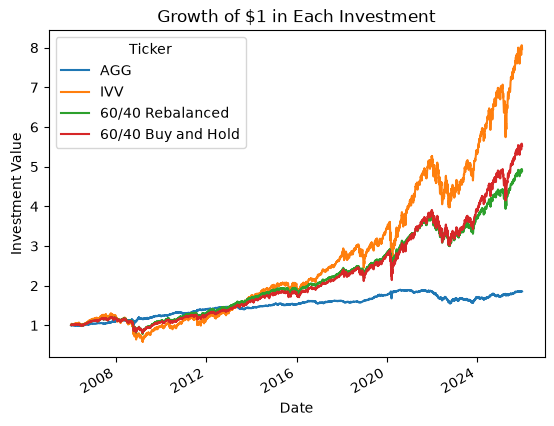

Ticker,AGG,IVV,60/40 Rebalanced,60/40 Buy and Hold
Date,,,,
2025-12-31,1.856556,7.963791,4.901404,5.520897


In [13]:
growth = investment.copy()
growth["60/40 Rebalanced"] = (1 + portfolio_6040).cumprod()
growth["60/40 Buy and Hold"] = buy_hold_value.loc[growth.index]

growth.plot()
plt.title("Growth of $1 in Each Investment")
plt.xlabel("Date")
plt.ylabel("Investment Value")
plt.show()

growth.tail(1)

The ending values of $1 invested were about $1.86 for AGG, $7.96 for IVV, $4.90 for the rebalanced 60/40 portfolio, and $5.52 for the buy&hold 60/40 portfolio.

<small>Reference: Project 1, Exercise 4; Project 2, Exercise 14; Project 4, Question 8.</small>

## Question 9

I calculated the correlations between the daily returns of the ETFs and both portfolios.

<small>Reference: Project 2, Exercise 13.</small>

In [14]:
all_returns = pd.concat(
    [
        returns["IVV"],
        returns["AGG"],
        portfolio_6040,
        buy_hold_returns,
    ],
    axis=1,
)

all_returns.columns = [
    "IVV",
    "AGG",
    "60/40 Rebalanced",
    "60/40 Buy and Hold",
]

all_returns.corr()

,IVV,AGG,60/40 Rebalanced,60/40 Buy and Hold
IVV,1.000000,-0.022210,0.983360,0.969786
AGG,-0.022210,1.000000,0.159784,0.138997
60/40 Rebalanced,0.983360,0.159784,1.000000,0.982820
60/40 Buy and Hold,0.969786,0.138997,0.982820,1.000000


The two 60/40 portfolios were highly correlated with IVV (about 0.98 for the rebalanced portfolio and 0.97 for buy&hold). 

Their returns may therefore still move much like IVV during market changes. AGG had much lower correlations with the portfolios.

 An investor seeking more diversification might consider how much AGG to include, while remembering that correlation can change over time.

<small>Reference: Project 2, Exercise 13; Project 4, Question 9.</small>

## Question 10

I used the return averages and standard deviations to simulate possible outcomes for the 4 investments over 1 and 5 years.

<small>Reference: Project 3, Exercise 9; Project 4, Question 10.</small>

In [15]:
np.random.seed(1)

L = 100_000
dt = 1 / 252
n_days = 252 * 5

mu = all_returns.mean().values * 252
sigma = all_returns.std().values * np.sqrt(252)
names = all_returns.columns

simulated_value = np.ones((L, len(names)))

for day in range(1, n_days + 1):
    z = np.random.normal(size=(L, len(names)))

    simulated_value *= np.exp(
        (mu - 0.5 * sigma ** 2) * dt
        + sigma * np.sqrt(dt) * z
    )

    if day == 252:
        one_year = simulated_value.copy()

five_year = simulated_value.copy()

results = []

for years, values in [("1 year", one_year), ("5 years", five_year)]:
    for i, name in enumerate(names):
        for loss in [0.10, 0.25]:
            final_values = values[:, i]
            below_cutoff = final_values < (1 - loss)

            probability = below_cutoff.mean()
            expected_loss = (
                (1 - final_values[below_cutoff]).mean()
                if below_cutoff.any()
                else np.nan
            )

            results.append([
                name,
                years,
                loss,
                probability,
                expected_loss,
            ])

simulation_results = pd.DataFrame(
    results,
    columns=[
        "Investment",
        "Time",
        "Loss Threshold",
        "Probability",
        "Average Loss if Threshold Is Hit",
    ],
)

simulation_results

,Investment,Time,Loss Threshold,Probability,Average Loss if Threshold Is Hit
0,IVV,1 year,0.10,0.13786,0.181915
1,IVV,1 year,0.25,0.02168,0.299891
2,AGG,1 year,0.10,0.00521,0.114784
3,AGG,1 year,0.25,0.00000,NaN
4,60/40 Rebalanced,1 year,0.10,0.05588,0.143181
5,60/40 Rebalanced,1 year,0.25,0.00081,0.275109
6,60/40 Buy and Hold,1 year,0.10,0.06448,0.147518
7,60/40 Buy and Hold,1 year,0.25,0.00146,0.271207
8,IVV,5 years,0.10,0.07295,0.250013
9,IVV,5 years,0.25,0.03080,0.360981


The chance of a loss greater than 10% went down over five years for IVV and both 60/40 portfolios, but increased for AGG.

 With positive average returns, growth over a longer period can make a fixed 10% loss less likely for some investments, even as uncertainty accumulates.

 The chance of a loss greater than 25% rose for all four investments, and the average loss when a threshold was crossed was generally larger over five years.
 
 The exact probabilities come from this simulation.

 No AGG paths crossed 25% cutoff after 1 year, so its conditional average loss is unavailable.

<small>Reference: Project 3, Exercise 9; Project 4, Question 10.</small>

## Question 11

I repeated the one-year simulation with a market event after six months. The event loss was between 0% and 25%, and volatility increased after the event.

<small>Reference: Project 3, Exercise 9; Project 4, Question 11.</small>

In [16]:
event_value = np.ones((L, len(names)))
sigma_after = 1.5 * sigma

for day in range(1, 253):
    if day <= 126:
        current_sigma = sigma
    else:
        current_sigma = sigma_after

    z = np.random.normal(size=(L, len(names)))

    event_value *= np.exp(
        (mu - 0.5 * current_sigma ** 2) * dt
        + current_sigma * np.sqrt(dt) * z
    )

    if day == 126:
        event_loss = np.random.uniform(0, 0.25, size=(L, 1))
        event_value *= (1 - event_loss)

event_results = []

for i, name in enumerate(names):
    for loss in [0.10, 0.25]:
        final_values = event_value[:, i]
        below_cutoff = final_values < (1 - loss)

        probability = below_cutoff.mean()
        expected_loss = (
            (1 - final_values[below_cutoff]).mean()
            if below_cutoff.any()
            else np.nan
        )

        event_results.append([
            name,
            loss,
            probability,
            expected_loss,
        ])

event_simulation_results = pd.DataFrame(
    event_results,
    columns=[
        "Investment",
        "Loss Threshold",
        "Probability",
        "Average Loss if Threshold Is Hit",
    ],
)

event_simulation_results

,Investment,Loss Threshold,Probability,Average Loss if Threshold Is Hit
0,IVV,0.10,0.40959,0.245394
1,IVV,0.25,0.17550,0.342658
2,AGG,0.10,0.49884,0.175207
3,AGG,0.25,0.04453,0.276328
4,60/40 Rebalanced,0.10,0.40029,0.199481
5,60/40 Rebalanced,0.25,0.09376,0.305018
6,60/40 Buy and Hold,0.10,0.39350,0.204389
7,60/40 Buy and Hold,0.25,0.10129,0.309130


The event pushed the chance of a loss over 10% much higher for all four investments: about 41% for IVV, 50% for AGG, and 39–40% for the two portfolios. 

For losses over 25%, IVV had the highest chance at 17.6%; AGG was about 4.5%, and the portfolios were about 9–10%.

 When a threshold was crossed, average losses ranged from about 17.5–24.5% for the 10% cutoff and 27.6–34.3% for the 25% cutoff.

<small>Reference: Project 3, Exercise 9; Project 4, Questions 10–11.</small>

## Question 12

I downloaded daily prices for C and CIZN and calculated their returns to compare them with IVV and AGG.

<small>Reference: Project 2, Exercises 1–2; “5. Downloading price data” class notebook; Week 8 regression material.</small>

In [17]:
bank_prices = yf.download(
    ["C", "CIZN"],
    start="2005-12-01",
    end="2026-01-01",
    auto_adjust=False
)

bank_returns = bank_prices["Adj Close"].pct_change()
bank_returns = bank_returns.loc["2006-01-01":"2025-12-31"]

q12_returns = pd.concat(
    [bank_returns, returns[["IVV", "AGG"]]],
    axis=1,
    join="inner"
).dropna()

q12_returns.head()

[*********************100%***********************]  2 of 2 completed


Ticker,C,CIZN,IVV,AGG
Date,,,,
2006-01-03,0.015661,0.006652,0.017326,0.000497
2006-01-04,-0.018462,0.000000,0.005204,0.002384
2006-01-05,0.004961,0.000000,0.000784,0.000000
2006-01-06,0.000000,0.000000,0.008308,-0.002280
2006-01-09,-0.004731,-0.008811,0.002565,0.001093


In [18]:
    
q12_corr = q12_returns.corr().loc[["C", "CIZN"], ["IVV", "AGG"]]

q12_corr

Ticker,IVV,AGG
Ticker,,
C,0.654980,-0.067695
CIZN,0.083029,0.013986


C had a stronger relationship with IVV than with AGG. CIZN’s correlations with both ETFs were close to zero, so its daily returns had little linear relationship with either ETF in this sample.

<small>Reference: Project 2, Exercise 13; Project 4, Question 12(a).</small>

In [19]:
import statsmodels.api as sm

reg_models = {}
regression_rows = []

for stock in ["C", "CIZN"]:
    for etf in ["IVV", "AGG"]:
        X = sm.add_constant(q12_returns[etf])
        y = q12_returns[stock]

        model = sm.OLS(y, X).fit()
        reg_models[(stock, etf)] = model

        alpha_ci = model.conf_int().loc["const"]
        beta_ci = model.conf_int().loc[etf]

        regression_rows.append({
            "Stock": stock,
            "ETF": etf,
            "Alpha": model.params["const"],
            "Alpha t-stat": model.tvalues["const"],
            "Alpha p-value": model.pvalues["const"],
            "Alpha 95% CI": f"({alpha_ci.iloc[0]:.6f}, {alpha_ci.iloc[1]:.6f})",
            "Beta": model.params[etf],
            "Beta t-stat": model.tvalues[etf],
            "Beta p-value": model.pvalues[etf],
            "Beta 95% CI": f"({beta_ci.iloc[0]:.6f}, {beta_ci.iloc[1]:.6f})",
        })

regression_table = pd.DataFrame(regression_rows)
regression_table.round(6)

,Stock,ETF,Alpha,Alpha t-stat,Alpha p-value,Alpha 95% CI,Beta,Beta t-stat,Beta p-value,Beta 95% CI
0,C,IVV,-0.000533,-1.605880,0.108363,"(-0.001184, 0.000118)",1.681476,61.468148,0.000000,"(1.627848, 1.735104)"
1,C,AGG,0.000365,0.833899,0.404377,"(-0.000494, 0.001225)",-0.629552,-4.811657,0.000002,"(-0.886053, -0.373050)"
2,CIZN,IVV,0.000160,0.489571,0.624459,"(-0.000482, 0.000803)",0.159626,5.908428,0.000000,"(0.106662, 0.212591)"
3,CIZN,AGG,0.000226,0.685828,0.492853,"(-0.000419, 0.000870)",0.097406,0.991933,0.321278,"(-0.095105, 0.289918)"


None of the alpha estimates are statistically different from zero at the 5% level because their p-values are above 0.05 and their 95% confidence intervals include zero.

 C had a positive beta with IVV and a negative beta with AGG, and both estimates were statistically significant.
 
 CIZN had a small positive beta with IVV, while its beta with AGG was not statistically significant.

<small>Reference: Week 8 regression material; Project 4, Questions 12(b)–(c).</small>

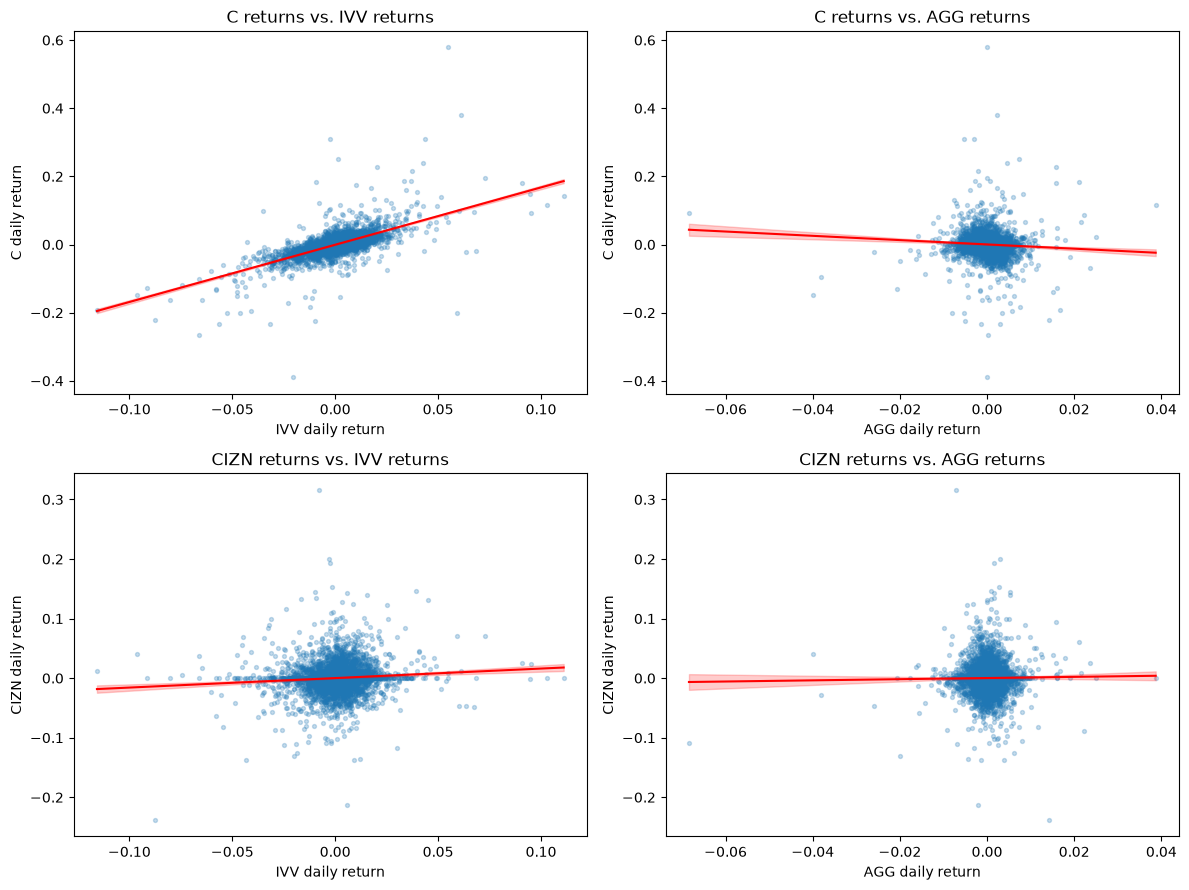

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (stock, etf) in zip(
    axes.flatten(),
    [("C", "IVV"), ("C", "AGG"), ("CIZN", "IVV"), ("CIZN", "AGG")]
):
    model = reg_models[(stock, etf)]
    x = q12_returns[etf]
    X = sm.add_constant(x)
    prediction = model.get_prediction(X).summary_frame()

    order = np.argsort(x.values)
    x_sorted = x.iloc[order]
    prediction_sorted = prediction.iloc[order]

    ax.scatter(x, q12_returns[stock], alpha=0.25, s=8)
    ax.plot(x_sorted, prediction_sorted["mean"], color="red")
    ax.fill_between(
        x_sorted,
        prediction_sorted["mean_ci_lower"],
        prediction_sorted["mean_ci_upper"],
        color="red",
        alpha=0.2
    )

    ax.set_title(f"{stock} returns vs. {etf} returns")
    ax.set_xlabel(f"{etf} daily return")
    ax.set_ylabel(f"{stock} daily return")

plt.tight_layout()
plt.show()

The plots show C has a clear positive relationship with IVV and a slight negative relationship with AGG. CIZN’s relationship with IVV is much smaller, and its relationship with AGG is close to zero.

 This matches the beta estimates: C’s beta was larger in absolute value, while CIZN’s beta with AGG was not statistically significant.
 
  None of the alpha estimates were statistically different from zero.

<small>Reference: Project 2, Exercise 3; Week 8 regression material; Project 4, Questions 12(d)–(e).</small>

In [21]:
simultaneous_models = {}
simultaneous_rows = []

for stock in ["C", "CIZN"]:
    X = sm.add_constant(q12_returns[["IVV", "AGG"]])
    y = q12_returns[stock]

    model = sm.OLS(y, X).fit()
    simultaneous_models[stock] = model

    simultaneous_rows.append({
        "Stock": stock,
        "Alpha": model.params["const"],
        "Beta IVV": model.params["IVV"],
        "Beta AGG": model.params["AGG"],
    })

simultaneous_table = pd.DataFrame(simultaneous_rows)
simultaneous_table.round(6)

,Stock,Alpha,Beta IVV,Beta AGG
0,C,-0.000468,1.678444,-0.494513
1,CIZN,0.000146,0.160302,0.110303


When IVV and AGG were included together, C’s beta estimates were about 1.678 for IVV and -0.495 for AGG. In the separate regressions, C’s AGG beta was about -0.630. 

The simultaneous regression measures the relationship with AGG while holding IVV constant; the separate regression does not. IVV and AGG had a small negative correlation, and C had a large IVV beta, which can help explain the change in its AGG estimate.

CIZN’s estimates changed less.

Both companies are banks, but their estimated relationships with the ETFs were different: C had a stronger relationship with IVV, while CIZN’s betas were smaller. 

CIZN’s downloaded return series also has many daily returns shown as zero, so lower trading activity or data limitations may contribute to its weaker measured relationships. 

These regressions suggest possible explanations but do not prove what caused the differences.

<small>Reference: Project 2, Exercise 13; Week 8 regression material; Project 4, Question 12.</small>